In [116]:
import ast

import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv("../data/raw/ptbxl_database.csv", index_col="ecg_id")
df.head()

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [38]:
# Number of ECGs
df.shape[0]

21799

In [39]:
# Number of unique patient IDs
df.patient_id.nunique()

18869

In [40]:
# Descriptive values "age"
df.age.describe()

count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64

In [41]:
# How many ECGs per Fold?
df.strat_fold.value_counts()

strat_fold
10    2198
3     2192
9     2183
2     2181
7     2176
1     2175
5     2174
4     2174
8     2173
6     2173
Name: count, dtype: int64

21,799 ECGs from 18,869 patients; some patients have multiple recordings, so splits must be patient-separated. Ages above 89 are encoded as 300.

In [42]:
# Ages above 89 are encoded as 300; map them to 90
df["age"] = df["age"].replace(300, 90)
df.age.describe()

count    21799.000000
mean        59.946695
std         17.011384
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max         90.000000
Name: age, dtype: float64

In [43]:
df.sex.value_counts()  # 0: male, 1: female

sex
0    11354
1    10445
Name: count, dtype: int64

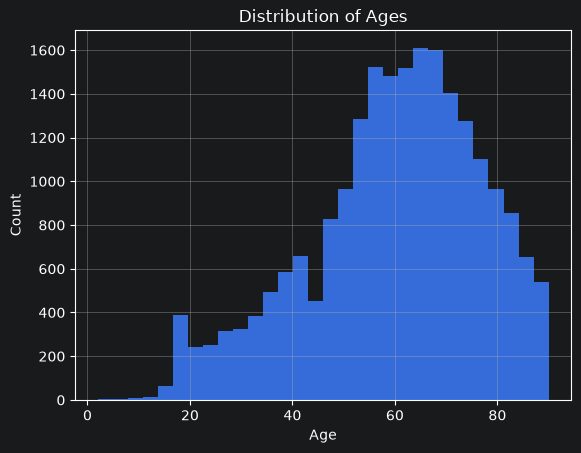

In [44]:
df["age"].hist(bins=30)
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Distribution of Ages")
plt.show()

Histogram of ages stops at 90 due to replacing age above 89 with 90.

In [45]:
df["scp_codes"].head()

ecg_id
1    {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
2                {'NORM': 80.0, 'SBRAD': 0.0}
3                  {'NORM': 100.0, 'SR': 0.0}
4                  {'NORM': 100.0, 'SR': 0.0}
5                  {'NORM': 100.0, 'SR': 0.0}
Name: scp_codes, dtype: str

In [46]:
type(df["scp_codes"].iloc[0])

str

In [47]:
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

In [48]:
type(df["scp_codes"].iloc[0])

dict

In [49]:
df["scp_codes"].head()

ecg_id
1    {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
2                {'NORM': 80.0, 'SBRAD': 0.0}
3                  {'NORM': 100.0, 'SR': 0.0}
4                  {'NORM': 100.0, 'SR': 0.0}
5                  {'NORM': 100.0, 'SR': 0.0}
Name: scp_codes, dtype: object

In [50]:
norm_ecg = df["scp_codes"].apply(lambda d: "NORM" in d).sum()  # ECGs that contain NORM
print(norm_ecg)

9514


In [51]:
df.shape[0] - norm_ecg  # ECGs that do not contain NORM

np.int64(12285)

In [80]:
statements = pd.read_csv("../data/raw/scp_statements.csv", index_col=0)

In [81]:
statements.head()

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [82]:
statements = statements[statements["diagnostic"] == 1]
statements["diagnostic_class"].unique()  # Diagnostic classes

<StringArray>
['STTC', 'NORM', 'MI', 'HYP', 'CD']
Length: 5, dtype: str

In [83]:
import numpy as np


def get_superclasses(codes: dict) -> list:
    superclasses = []
    for code in codes:
        if code in statements.index and code is not np.nan:
            superclasses.append(statements.loc[code, "diagnostic_class"])

    return list(set(superclasses))

In [84]:
get_superclasses(df.loc[45, "scp_codes"])

['HYP', 'CD']

In [85]:
df["superclasses"] = df["scp_codes"].apply(get_superclasses)

In [87]:
df["superclasses"]

ecg_id
1        [NORM]
2        [NORM]
3        [NORM]
4        [NORM]
5        [NORM]
          ...  
21833    [STTC]
21834    [NORM]
21835    [STTC]
21836    [NORM]
21837    [NORM]
Name: superclasses, Length: 21799, dtype: object

In [88]:
df["superclasses"].value_counts()  # Count of superclasses

superclasses
[NORM]                 9069
[MI]                   2532
[STTC]                 2400
[CD]                   1708
[MI, CD]               1297
[STTC, HYP]             781
[STTC, MI]              599
[HYP]                   535
[STTC, CD]              471
[]                      411
[NORM, CD]              407
[STTC, MI, HYP]         361
[HYP, CD]               300
[STTC, MI, CD]          223
[STTC, HYP, CD]         211
[MI, HYP]               183
[STTC, MI, HYP, CD]     156
[MI, HYP, CD]           117
[STTC, NORM]             28
[STTC, NORM, CD]          5
[NORM, HYP, CD]           2
[NORM, HYP]               2
[NORM, MI, HYP, CD]       1
Name: count, dtype: int64

Exclude ECGs with no superclasses in training, they don't show normal/abnormal ECG but are rather not labelled.

In [92]:
df["superclasses"].explode().value_counts()

superclasses
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Name: count, dtype: int64

In [90]:
df["superclasses"].apply(len)

ecg_id
1        1
2        1
3        1
4        1
5        1
        ..
21833    1
21834    1
21835    1
21836    1
21837    1
Name: superclasses, Length: 21799, dtype: int64

In [97]:
df["superclasses"].apply(len).value_counts()

superclasses
1    16244
2     4068
3      919
0      411
4      157
Name: count, dtype: int64

Text(0.5, 1.0, 'Distribution of Superclasses')

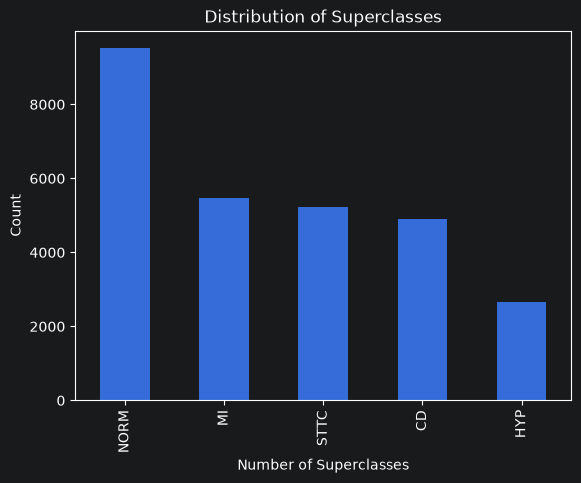

In [96]:
df["superclasses"].explode().value_counts().plot.bar()
plt.xlabel("Number of Superclasses")
plt.ylabel("Count")
plt.title("Distribution of Superclasses")

1. Class distribution is highly imbalanced, with the majority of ECGs being normal.
Stratified splits necessary for training.
2. Accuracy is not a good metric for evaluation, use AUROC instead
2. Use class weights for training to account for imbalance

In [105]:
import wfdb

norm_ids = df[df["superclasses"].apply(lambda classes: classes == ["NORM"])]
mi_ids = df[df["superclasses"].apply(lambda classes: classes == ["MI"])]

norm_ecg, norm_meta = wfdb.rdsamp("../data/raw/" + norm_ids["filename_lr"].iloc[0])
mi_ecg, mi_meta = wfdb.rdsamp("../data/raw/" + mi_ids["filename_lr"].iloc[0])

In [131]:
def plot_ecg(signal, meta, title):
    t = np.arange(signal.shape[0]) / meta["fs"]
    fig, axes = plt.subplots(12, 1, figsize=(12, 16), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(t, signal[:, i])
        ax.set_ylabel(meta["sig_name"][i])

    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(title)
    plt.show()

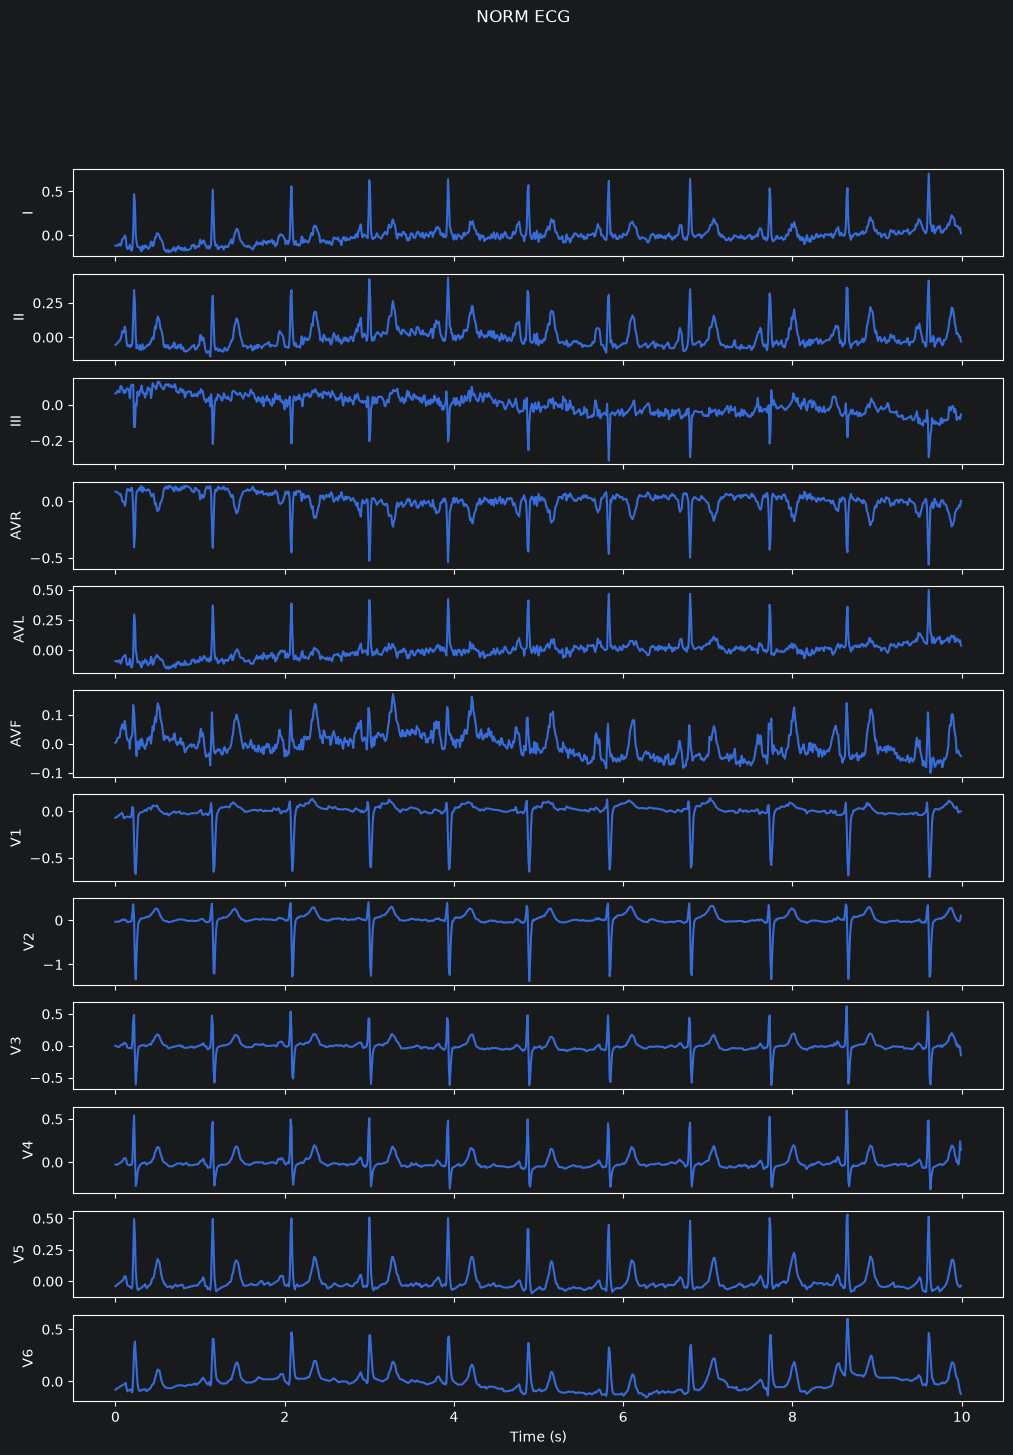

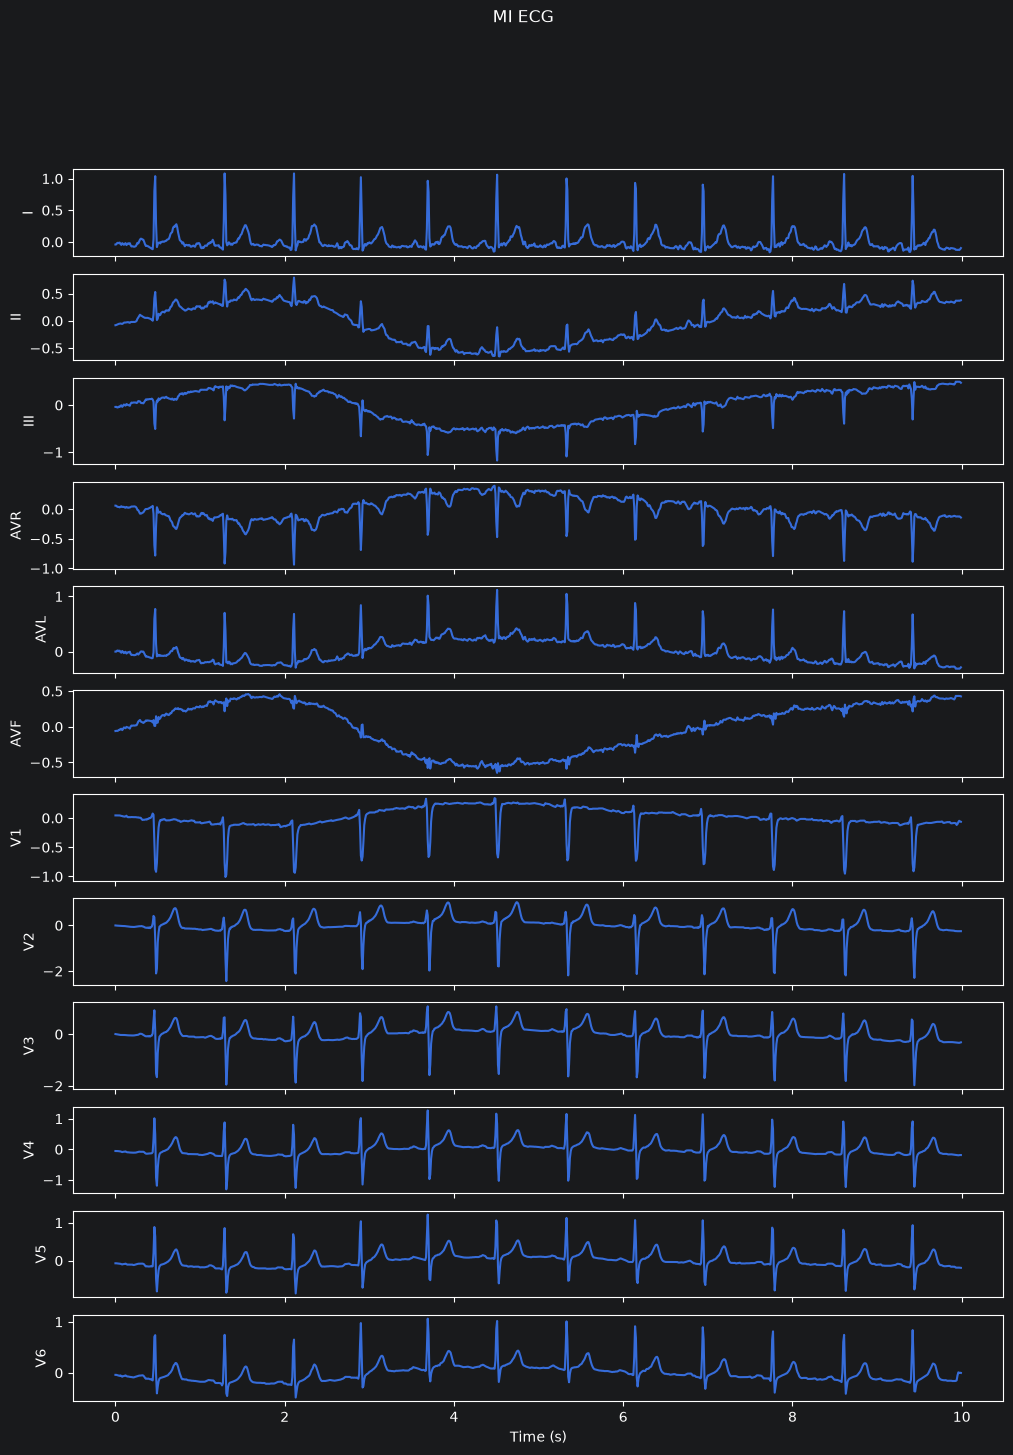

In [132]:
plot_ecg(norm_ecg, norm_meta, "NORM ECG")
plot_ecg(mi_ecg, mi_meta, "MI ECG")

The MI example (ecg_id 8, IMI) shows low-frequency baseline wander in II, III and aVF. The metadata column baseline_drift confirms this is a recording artifact, not a disease feature. Noise could be a confounder; a high-pass filter may help later.

## Split sanity check: patient overlap

In [2]:
from ecg.data import load_metadata, split_by_fold

df = load_metadata("../data/raw/ptbxl_database.csv")
train_df, val_df, test_df = split_by_fold(df)

patient_ids_train = set(train_df["patient_id"])
patient_ids_val = set(val_df["patient_id"])
patient_ids_test = set(test_df["patient_id"])

assert len(patient_ids_train & patient_ids_val) == 0, (
    "Train and validation sets have overlapping patient IDs"
)
assert len(patient_ids_train & patient_ids_test) == 0, (
    "Train and test sets have overlapping patient IDs"
)
assert len(patient_ids_val & patient_ids_test) == 0, (
    "Validation and test sets have overlapping patient IDs"
)